# Daily NYC taxi demand features

Prepare all 12 months of 2024 yellow taxi trips with a lazy Polars pipeline.
One row represents one pickup date; `ride_count` is the target.

[Assignment](https://github.com/j-adamczyk/MLOps_course_AGH/blob/master/lab03/HOMEWORK.md) · [TLC trip data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) · [Data dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

## 1. Load data

In [1]:
import os

# Limit parallel scans and decompression to keep RAM use predictable.
os.environ["POLARS_MAX_THREADS"] = "2"

In [2]:
from datetime import datetime, time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

DATA_DIR = Path("../../lab03/data")
MONTHS = range(1, 13)
START = datetime(2024, 1, 1)
END = datetime(2025, 1, 1)
MONEY_COLUMNS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]
PAYMENT_CARD = 1
PAYMENT_CASH = 2
PAYMENT_CATEGORIES = ["card", "cash", "other"]
VENDOR_IDS = [1, 2, 6, 7]
RATE_CODES = [1, 2, 3, 4, 5, 6]
MAX_PASSENGERS = 6
MAX_AMOUNT = 1000
PICKUP = "tpep_pickup_datetime"
DROPOFF = "tpep_dropoff_datetime"

DATA_DIR.mkdir(parents=True, exist_ok=True)
urls = {
    f"{month}.parquet": f"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-{month:02}.parquet"
    for month in MONTHS
}
urls["taxi_zone_lookup.csv"] = (
    "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
)
for name, url in urls.items():
    destination = DATA_DIR / name
    if destination.exists():
        continue
    temporary = destination.with_suffix(destination.suffix + ".part")
    urlretrieve(url, temporary)
    temporary.replace(destination)

zones = (
    pl.read_csv(DATA_DIR / "taxi_zone_lookup.csv")
    .select(
        pl.col("LocationID").cast(pl.UInt16),
        pl.col("Borough")
        .str.to_lowercase()
        .str.replace_all(r"[^a-z0-9]+", "_")
        .cast(pl.Categorical),
    )
    .to_dummies("Borough")
)
borough_columns = [name for name in zones.columns if name.startswith("Borough_")]
scans = [
    pl.scan_parquet(DATA_DIR / f"{month}.parquet").with_columns(
        pl.col(PICKUP, DROPOFF).dt.cast_time_unit("us")
    )
    for month in MONTHS
]

## 2–4. Clean, transform, and aggregate

The actual passenger column is `passenger_count`. Fill missing counts with 1,
remove zero/negative counts, and cap at 6. Keep durations from 0 through 2 hours;
reject reversed timestamps. Take absolute financial values before applying the
$1000 limit. Rows with missing financial values cannot satisfy this limit.

Use the dictionary's vendor codes; discard rate 99 because it denotes a missing
or unknown rate. Map payment codes other than card/cash to `other`.
Rush intervals include both endpoints, use pickup time, and apply Monday–Friday.

Encode boroughs on the small lookup table, then join and sum the indicators.
Unmatched location IDs use the `unknown` bucket.
Payment indicators are equivalent lazy dummy expressions. Exact grouped median needs an in-memory operation in Polars. Compute it
separately using only date and distance, before joining or encoding boroughs.
The remaining daily aggregates stream in a second pass over the source files.

In [3]:
pickup_time = pl.col(PICKUP).dt.time()

rides = (
    pl.concat(scans, how="vertical_relaxed")
    .filter(
        pl.col(PICKUP).is_between(START, END, closed="left"),
        pl.col(DROPOFF) <= END,
        (pl.col(DROPOFF) - pl.col(PICKUP)).is_between(
            pl.duration(), pl.duration(hours=2)
        ),
        pl.col("VendorID").is_in(VENDOR_IDS),
        pl.col("RatecodeID").is_in(RATE_CODES),
    )
    .with_columns(
        pl.col("passenger_count").fill_null(1).clip(upper_bound=MAX_PASSENGERS),
        pl.col(MONEY_COLUMNS).abs(),
    )
    .filter(
        pl.col("passenger_count") > 0,
        pl.all_horizontal(pl.col(MONEY_COLUMNS) <= MAX_AMOUNT),
    )
    .with_columns(
        pl.col("passenger_count").cast(pl.UInt8),
        pl.col("PULocationID", "DOLocationID").cast(pl.UInt16, strict=False),
        pl.when(pl.col("payment_type") == PAYMENT_CARD)
        .then(pl.lit("card"))
        .when(pl.col("payment_type") == PAYMENT_CASH)
        .then(pl.lit("cash"))
        .otherwise(pl.lit("other"))
        .cast(pl.Enum(PAYMENT_CATEGORIES))
        .alias("payment_type"),
        date=pl.col(PICKUP).dt.date(),
        is_airport_ride=pl.col("Airport_fee") > 0,
        is_rush_hour=(pl.col(PICKUP).dt.weekday() <= 5)
        & (
            pickup_time.is_between(time(6, 30), time(9, 30))
            | pickup_time.is_between(time(15, 30), time(20))
        ),
    )
)

# Exact median needs memory; keep only its two input columns.
median_distances = (
    rides.select("date", "trip_distance")
    .group_by("date")
    .agg(median_distance=pl.col("trip_distance").median())
    .collect(engine="streaming")
)

pipeline = (
    rides.join(
        zones.lazy().rename(
            {name: name.replace("Borough_", "pickup_") for name in borough_columns}
        ),
        left_on="PULocationID",
        right_on="LocationID",
        how="left",
    )
    .join(
        zones.lazy().rename(
            {name: name.replace("Borough_", "dropoff_") for name in borough_columns}
        ),
        left_on="DOLocationID",
        right_on="LocationID",
        how="left",
    )
    .with_columns(
        [
            (pl.col("payment_type") == category)
            .cast(pl.UInt8)
            .alias(f"payment_{category}")
            for category in PAYMENT_CATEGORIES
        ]
    )
    .group_by("date")
    .agg(
        ride_count=pl.len(),
        airport_ride_count=pl.col("is_airport_ride").sum(),
        rush_hour_ride_count=pl.col("is_rush_hour").sum(),
        average_fare_amount=pl.col("fare_amount").mean(),
        total_amount=pl.col("total_amount").sum(),
        congestion_surcharge=pl.col("congestion_surcharge").sum(),
        passenger_count=pl.col("passenger_count").sum(),
        **{
            f"total_amount_{category}": pl.col("total_amount")
            .filter(pl.col("payment_type") == category)
            .sum()
            for category in PAYMENT_CATEGORIES
        },
        **{
            name: pl.col(name)
            .fill_null(int(name.endswith("_unknown")))
            .cast(pl.UInt32)
            .sum()
            for name in (
                [f"payment_{category}" for category in PAYMENT_CATEGORIES]
                + [
                    name.replace("Borough_", prefix)
                    for prefix in ["pickup_", "dropoff_"]
                    for name in borough_columns
                ]
            )
        },
    )
    .join(median_distances.lazy(), on="date")
    .with_columns(
        quarter=pl.col("date").dt.quarter().cast(pl.UInt8),
        month=pl.col("date").dt.month().cast(pl.UInt8),
        day_of_month=pl.col("date").dt.day().cast(pl.UInt8),
        day_of_week=pl.col("date").dt.weekday().cast(pl.UInt8),
        is_weekend=pl.col("date").dt.weekday() > 5,
    )
    .sort("date")
)

dataset = pipeline.collect(engine="streaming")
dataset.write_parquet("dataset.parquet")

## 5. Inspect the daily dataset

Check one row per day and reconcile all encoded category counts and payment
amounts with their daily totals. Day of week uses ISO numbering: Monday = 1.

In [4]:
assert dataset.height == (END - START).days
assert dataset["date"].n_unique() == dataset.height
assert dataset["date"].is_sorted()
assert dataset.null_count().sum_horizontal().item() == 0
for prefix in ["payment_", "pickup_", "dropoff_"]:
    assert dataset.select(
        (pl.sum_horizontal(pl.col(f"^{prefix}.*$")) == pl.col("ride_count")).all()
    ).item()
assert dataset.select(
    (
        (pl.sum_horizontal(pl.col("^total_amount_.*$")) - pl.col("total_amount")).abs()
        < 0.01
    ).all()
).item()

print("Shape:", dataset.shape)
dataset.head()

Shape: (366, 36)


date,ride_count,airport_ride_count,rush_hour_ride_count,average_fare_amount,total_amount,congestion_surcharge,passenger_count,total_amount_card,total_amount_cash,total_amount_other,payment_card,payment_cash,payment_other,pickup_bronx,pickup_brooklyn,pickup_ewr,pickup_manhattan,pickup_n_a,pickup_queens,pickup_staten_island,pickup_unknown,dropoff_bronx,dropoff_brooklyn,dropoff_ewr,dropoff_manhattan,dropoff_n_a,dropoff_queens,dropoff_staten_island,dropoff_unknown,median_distance,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,i64,f64,f64,f64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,f64,u8,u8,u8,u8,bool
2024-01-01,69541,8352,19360,22.184388,2.1793e6,156123.25,109013,1.7389e6,384662.67,55778.86,52846,14491,2204,60,627,21,59231,93,9235,3,271,559,3785,388,58579,605,5150,31,444,2.09,1,1,1,1,false
2024-01-02,71443,9828,30554,21.312124,2.2095e6,160615.0,102927,1.7617e6,396334.47,51441.03,54034,15387,2022,34,232,20,60126,54,10709,2,266,433,2979,319,62212,432,4651,32,385,1.8,1,1,2,2,false
2024-01-03,78399,9140,32924,19.968751,2.2900e6,177985.0,109805,1.8242e6,416241.57,49554.25,60176,16202,2021,48,301,16,67701,36,9981,1,315,498,3124,282,69273,395,4340,14,473,1.72,1,1,3,3,false
2024-01-04,97896,8270,43112,18.68711,2.7179e6,226627.5,134634,2.2134e6,444631.77,59823.2,77557,17994,2345,42,257,10,88136,39,9026,1,385,596,3089,226,88692,344,4386,14,549,1.73,1,1,4,4,false
2024-01-05,97958,7460,40150,18.114238,2.6451e6,227540.0,136260,2.1666e6,420694.52,57798.23,77801,17697,2460,47,298,8,88955,37,8218,1,394,536,2889,222,89122,342,4220,20,607,1.7,1,1,5,5,false


In [5]:
dataset.describe()

statistic,date,ride_count,airport_ride_count,rush_hour_ride_count,average_fare_amount,total_amount,congestion_surcharge,passenger_count,total_amount_card,total_amount_cash,total_amount_other,payment_card,payment_cash,payment_other,pickup_bronx,pickup_brooklyn,pickup_ewr,pickup_manhattan,pickup_n_a,pickup_queens,pickup_staten_island,pickup_unknown,dropoff_bronx,dropoff_brooklyn,dropoff_ewr,dropoff_manhattan,dropoff_n_a,dropoff_queens,dropoff_staten_island,dropoff_unknown,median_distance,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",98864.964481,8977.740437,29516.778689,19.78615,2.8671e6,230194.659891,133724.445355,2.4168e6,372218.143169,78106.016585,81012.60929,14922.142077,2930.213115,47.155738,385.013661,15.983607,88139.10929,59.322404,9903.234973,2.52459,312.620219,457.489071,3542.13388,284.52459,88604.502732,482.65847,5019.713115,25.188525,448.754098,1.703347,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15192.153609,1716.332502,19423.57868,1.206235,453436.342713,37862.272218,18670.169383,420924.176936,36192.125511,17242.867261,13981.172509,1357.233458,553.50793,13.635984,133.58606,7.71263,15101.368439,17.819334,1751.719263,1.677636,57.292717,60.135816,553.995931,73.624208,14602.673063,93.570255,680.876661,6.723093,92.085604,0.102153,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",46930.0,3355.0,0.0,16.623276,1.3081e6,107820.0,73723.0,978705.28,240633.43,41303.84,33594.0,10244.0,1656.0,22.0,167.0,2.0,41627.0,23.0,4814.0,0.0,149.0,312.0,1663.0,122.0,41529.0,260.0,2739.0,9.0,192.0,1.5,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",88657.0,7869.0,0.0,18.945217,2.5439e6,203501.0,121081.0,2.1289e6,352425.45,65781.9,71633.0,14108.0,2566.0,37.0,288.0,10.0,76908.0,45.0,8741.0,1.0,273.0,415.0,3181.0,236.0,78336.0,416.0,4569.0,20.0,390.0,1.64,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",99489.0,9018.0,38944.0,19.751554,2.8746e6,232817.5,132914.0,2.4310e6,375876.77,79216.96,82258.0,14965.0,2909.0,45.0,353.0,15.0,89401.0,58.0,9854.0,2.0,310.0,451.0,3494.0,275.0,89785.0,480.0,5029.0,25.0,444.0,1.69,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",109654.0,10144.0,44107.0,20.549493,3.1880e6,256939.5,145601.0,2.6994e6,398461.95,90101.99,90472.0,15832.0,3271.0,54.0,443.0,20.0,99037.0,70.0,11056.0,3.0,347.0,492.0,3877.0,335.0,98951.0,545.0,5511.0,30.0,515.0,1.75,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",140079.0,14903.0,55965.0,24.370708,4.4077e6,330475.0,198656.0,3.8619e6,449947.01,123886.72,119382.0,17994.0,4596.0,129.0,939.0,47.0,127844.0,125.0,15890.0,8.0,505.0,669.0,5544.0,583.0,127102.0,716.0,6710.0,51.0,718.0,2.2,4.0,12.0,31.0,7.0,1.0


In [6]:
print(dataset.schema)

Schema({'date': Date, 'ride_count': UInt32, 'airport_ride_count': UInt32, 'rush_hour_ride_count': UInt32, 'average_fare_amount': Float64, 'total_amount': Float64, 'congestion_surcharge': Float64, 'passenger_count': Int64, 'total_amount_card': Float64, 'total_amount_cash': Float64, 'total_amount_other': Float64, 'payment_card': UInt32, 'payment_cash': UInt32, 'payment_other': UInt32, 'pickup_bronx': UInt32, 'pickup_brooklyn': UInt32, 'pickup_ewr': UInt32, 'pickup_manhattan': UInt32, 'pickup_n_a': UInt32, 'pickup_queens': UInt32, 'pickup_staten_island': UInt32, 'pickup_unknown': UInt32, 'dropoff_bronx': UInt32, 'dropoff_brooklyn': UInt32, 'dropoff_ewr': UInt32, 'dropoff_manhattan': UInt32, 'dropoff_n_a': UInt32, 'dropoff_queens': UInt32, 'dropoff_staten_island': UInt32, 'dropoff_unknown': UInt32, 'median_distance': Float64, 'quarter': UInt8, 'month': UInt8, 'day_of_month': UInt8, 'day_of_week': UInt8, 'is_weekend': Boolean})


### Distribution and daily demand

Both plots describe trips retained by the cleaning rules, rather than all raw
TLC records.

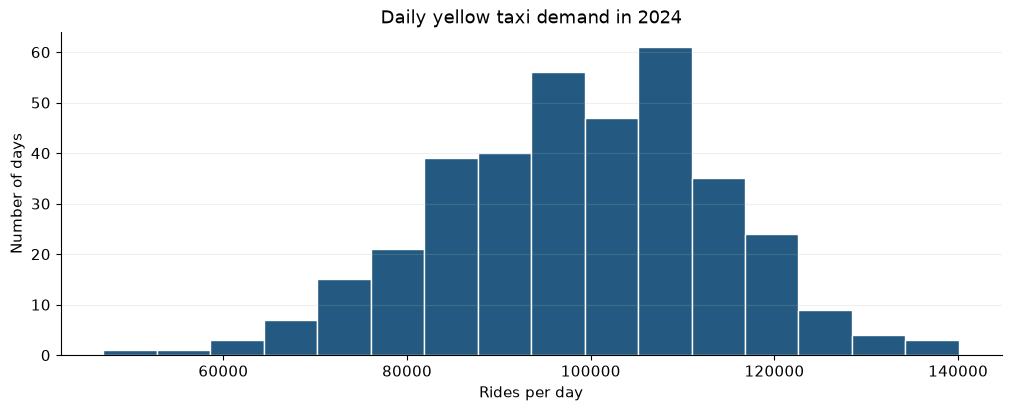

In [7]:
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
PLOT_COLOR = "#245a81"

fig, ax = plt.subplots(layout="constrained")
ax.hist(dataset["ride_count"], bins="auto", color=PLOT_COLOR, edgecolor="white")
ax.set(
    title="Daily yellow taxi demand in 2024",
    xlabel="Rides per day",
    ylabel="Number of days",
)
ax.grid(axis="y", alpha=0.2)
plt.show()

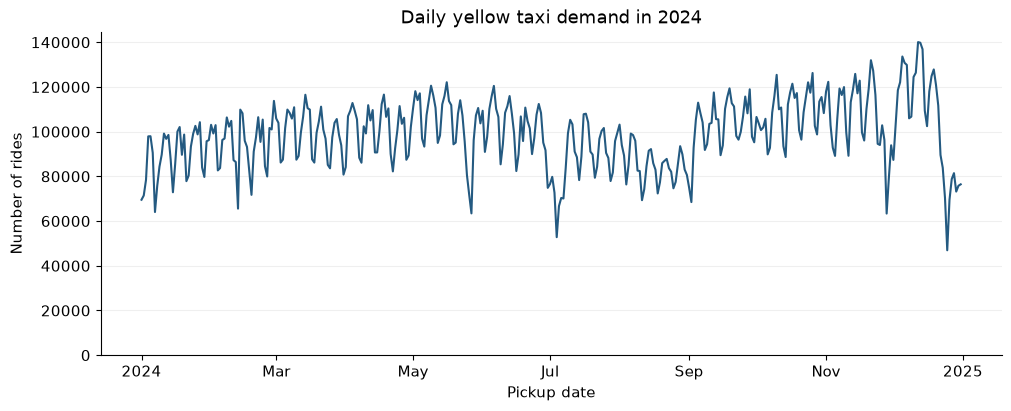

In [8]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(dataset["date"].to_list(), dataset["ride_count"], color=PLOT_COLOR)
ax.set(
    title="Daily yellow taxi demand in 2024",
    xlabel="Pickup date",
    ylabel="Number of rides",
    ylim=(0, None),
)
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(axis="y", alpha=0.2)
plt.show()